# 🛒 Sales Data Analysis 

**Goal:** Take messy sales data, clean it, and answer business questions with charts.

**Steps we will follow**
1. Load the data
2. Look at the data (find the problems)
3. Clean the data
4. Create new columns (feature engineering)
5. Answer business questions with charts
6. Write conclusions

**Libraries:** NumPy (numbers) · Pandas (tables) · Matplotlib & Seaborn (charts)

## Step 1: Import Libraries and Load Data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")   # nicer-looking charts

df = pd.read_csv("sales_data_raw.csv")   # read the file
df.head()                                # show first 5 rows

,order_id,order_date,customer_id,customer_name,customer_age,gender,region,city,category,product,quantity,unit_price,discount,payment_method,shipping_cost,delivery_days,customer_rating,sales_rep
0,ORD10569,24-Oct-2024,C1317,aarav singh,59.0,Female,South,Hyderabad,Home & Kitchen,Cookware Set,2,4777.11,0.15,UPI,99.0,4.0,4.0,Priya
1,ORD11332,29/12/2024,C1208,Swati Nair,25.0,Female,North,Chandigarh,Home & Kitchen,Air Fryer,3,6427.7,0.00,Debit Card,0.0,6.0,4.0,Rahul
2,ORD10708,04/09/2025,C1066,lakshmi nair,56.0,Female,North,Jaipur,Clothing,T-Shirt,1,783.52,0.05,UPI,49.0,11.0,5.0,Priya
3,ORD10879,31/03/2025,C1394,vivaan sharma,32.0,Male,North,Chandigarh,Electronics,Headphones,1,"₹2,790.37",0.05,credit card,49.0,-3.0,4.0,Rahul
4,ORD11483,2025-03-18,C1327,Swati Nair,45.0,Female,North,Jaipur,Clothing,Jacket,1,"₹3,638.79",0.00,UPI,49.0,4.0,5.0,Sneha


## Step 2: Look at the Data

**How big is the data? What are the column types?**

In [2]:
print("Rows, Columns:", df.shape)
df.info()

Rows, Columns: (1540, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1540 entries, 0 to 1539
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         1540 non-null   object 
 1   order_date       1540 non-null   object 
 2   customer_id      1540 non-null   object 
 3   customer_name    1540 non-null   object 
 4   customer_age     1433 non-null   float64
 5   gender           1540 non-null   object 
 6   region           1540 non-null   object 
 7   city             1493 non-null   object 
 8   category         1540 non-null   object 
 9   product          1540 non-null   object 
 10  quantity         1540 non-null   int64  
 11  unit_price       1540 non-null   object 
 12  discount         1466 non-null   float64
 13  payment_method   1478 non-null   object 
 14  shipping_cost    1479 non-null   float64
 15  delivery_days    1494 non-null   float64
 16  customer_rating  1400 non-null   f

**Are there missing values (NaN)?**

In [3]:
df.isnull().sum()

order_id             0
order_date           0
customer_id          0
customer_name        0
customer_age       107
gender               0
region               0
city                47
category             0
product              0
quantity             0
unit_price           0
discount            74
payment_method      62
shipping_cost       61
delivery_days       46
customer_rating    140
sales_rep           47
dtype: int64

**Are there duplicate rows?**

In [4]:
df.duplicated().sum()

40

**Are the text columns consistent?** (look for `north`, `NORTH`, ` North `, `Nrth` – all meant to be `North`)

In [5]:
df['region'].value_counts()

region
South      441
West       352
North      238
East       213
south       55
west        47
 WEST       42
north       40
 SOUTH      38
east        26
 NORTH      22
 EAST       21
Nrth         5
Name: count, dtype: int64

In [6]:
df['category'].value_counts()

category
Electronics        371
Clothing           275
Home & Kitchen     262
Furniture          185
Sports             182
ELECTRONICS         47
electronics         42
HOME & KITCHEN      28
home & kitchen      27
CLOTHING            27
clothing            24
FURNITURE           21
SPORTS              18
sports              17
furniture           14
Name: count, dtype: int64

### 📝 Problems we found
| # | Problem | Column |
|---|---|---|
| 1 | Duplicate rows | all |
| 2 | Same word written in different ways | region, category, payment_method, gender |
| 3 | Price is text like `₹1,200.50` | unit_price |
| 4 | Dates in different formats | order_date |
| 5 | Missing values | age, rating, discount, etc. |
| 6 | Impossible values (age 150, quantity -1) | age, quantity, delivery_days, discount |
| 7 | Price is far too high (typing mistake) | unit_price |

## Step 3: Clean the Data

We always work on a **copy**, so the original stays safe.

In [8]:
clean = df.copy()

### 3.1 Remove duplicate rows

In [9]:
clean = clean.drop_duplicates()
print("Rows after removing duplicates:", len(clean))

Rows after removing duplicates: 1500


### 3.2 Fix text columns
`strip()` removes extra spaces, `title()` makes it like `North`, `lower()` makes it small letters.

In [12]:
clean["region"]   = clean["region"].str.strip().str.title()
clean["region"]   = clean["region"].replace("Nrth", "North")      # fix typo
clean["category"] = clean["category"].str.strip().str.title()
clean["category"] = clean["category"].replace("HOME & KITCHEN", "Home & Kitchen")
clean["city"]     = clean["city"].str.strip().str.title()
clean["customer_name"] = clean["customer_name"].str.strip().str.title()

# Payment method: make lower case first, then map to proper names
clean["payment_method"] = clean["payment_method"].str.strip().str.lower()
clean["payment_method"] = clean["payment_method"].replace({
    "upi": "UPI", "credit card": "Credit Card", "debit card": "Debit Card",
    "cash on delivery": "Cash on Delivery", "net banking": "Net Banking"})

# Gender: M -> Male, F -> Female
clean["gender"] = clean["gender"].replace({"M": "Male", "F": "Female"})

print(clean["region"].unique())
print(clean["category"].unique())

['South' 'North' 'West' 'East']
['Home & Kitchen' 'Clothing' 'Electronics' 'Sports' 'Furniture']


### 3.3 Fix price (text → number)
Remove `₹` and `,` then convert to a number.

In [13]:
clean["unit_price"] = clean["unit_price"].astype(str).str.replace("₹", "").str.replace(",", "")
clean["unit_price"] = pd.to_numeric(clean["unit_price"])
clean["unit_price"].describe()

count    1.500000e+03
mean     1.284871e+04
std      6.721919e+04
min      6.301200e+02
25%      2.907677e+03
50%      4.840005e+03
75%      9.816542e+03
max      2.505906e+06
Name: unit_price, dtype: float64

### 3.4 Fix dates
Dates come in many formats. `format='mixed'` lets Pandas figure each one out.

In [14]:
clean["order_date"] = pd.to_datetime(clean["order_date"], format="mixed", dayfirst=True)
print(clean["order_date"].min(), "to", clean["order_date"].max())

2024-01-01 00:00:00 to 2025-12-31 00:00:00


### 3.5 Remove impossible values

In [15]:
# Quantity must be at least 1 -> remove bad rows
clean = clean[clean["quantity"] > 0]

# Age must be between 18 and 90 -> otherwise make it missing (NaN)
clean.loc[(clean["customer_age"] < 18) | (clean["customer_age"] > 90), "customer_age"] = np.nan

# Delivery days can't be negative -> make it missing
clean.loc[clean["delivery_days"] < 0, "delivery_days"] = np.nan

# Discount more than 30% is not allowed -> make it missing
clean.loc[clean["discount"] > 0.30, "discount"] = np.nan

### 3.6 Fix wrong (too high) prices
If a price is more than 3 times the normal price of that product, it is a typing mistake. We replace it with the product's median price.

In [16]:
median_price = clean.groupby("product")["unit_price"].transform("median")
too_high = clean["unit_price"] > 3 * median_price
print("Wrong prices found:", too_high.sum())

clean.loc[too_high, "unit_price"] = median_price

Wrong prices found: 7


### 3.7 Fill missing values
| Column | How we fill | Why |
|---|---|---|
| customer_age | median age | numeric column |
| delivery_days | median | numeric column |
| shipping_cost | median | numeric column |
| discount | 0 | no discount recorded = no discount |
| payment_method, city, sales_rep | "Unknown" | text column |
| customer_rating | **leave empty** | we should not invent customer opinions |

In [18]:
clean["customer_age"]   = clean["customer_age"].fillna(clean["customer_age"].median())
clean["delivery_days"]  = clean["delivery_days"].fillna(clean["delivery_days"].median())
clean["shipping_cost"]  = clean["shipping_cost"].fillna(clean["shipping_cost"].median())
clean["discount"]       = clean["discount"].fillna(0)
clean["payment_method"] = clean["payment_method"].fillna("Unknown")
clean["city"]           = clean["city"].fillna("Unknown")
clean["sales_rep"]      = clean["sales_rep"].fillna("Unknown")

clean.isnull().sum()    # only customer_rating should still have missing values

order_id             0
order_date           0
customer_id          0
customer_name        0
customer_age         0
gender               0
region               0
city                 0
category             0
product              0
quantity             0
unit_price           0
discount             0
payment_method       0
shipping_cost        0
delivery_days        0
customer_rating    128
sales_rep            0
dtype: int64

### 3.8 Final check

In [19]:
clean["customer_age"] = clean["customer_age"].astype(int)
clean["delivery_days"] = clean["delivery_days"].astype(int)
print("Clean data shape:", clean.shape)
clean.info()

Clean data shape: (1479, 18)
<class 'pandas.core.frame.DataFrame'>
Index: 1479 entries, 0 to 1539
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         1479 non-null   object        
 1   order_date       1479 non-null   datetime64[ns]
 2   customer_id      1479 non-null   object        
 3   customer_name    1479 non-null   object        
 4   customer_age     1479 non-null   int32         
 5   gender           1479 non-null   object        
 6   region           1479 non-null   object        
 7   city             1479 non-null   object        
 8   category         1479 non-null   object        
 9   product          1479 non-null   object        
 10  quantity         1479 non-null   int64         
 11  unit_price       1479 non-null   float64       
 12  discount         1479 non-null   float64       
 13  payment_method   1479 non-null   object        
 14  shipping_cost   

## Step 4: Feature Engineering (create new columns)
New columns make analysis easier.

In [20]:
# Revenue = price x quantity, minus discount
clean["revenue"] = clean["unit_price"] * clean["quantity"] * (1 - clean["discount"])

# Date parts
clean["year"]       = clean["order_date"].dt.year
clean["month"]      = clean["order_date"].dt.month
clean["month_name"] = clean["order_date"].dt.strftime("%b")
clean["year_month"] = clean["order_date"].dt.strftime("%Y-%m")

# Age group (put ages into buckets)
clean["age_group"] = pd.cut(clean["customer_age"],
                            bins=[17, 25, 35, 45, 55, 100],
                            labels=["18-25", "26-35", "36-45", "46-55", "55+"])

# Fast or slow delivery (using NumPy)
clean["delivery_type"] = np.where(clean["delivery_days"] <= 4, "Fast", "Slow")

clean[["order_date", "unit_price", "quantity", "discount", "revenue", "age_group", "delivery_type"]].head()

,order_date,unit_price,quantity,discount,revenue,age_group,delivery_type
0,2024-10-24,4777.11,2,0.15,8121.0870,55+,Fast
1,2024-12-29,6427.70,3,0.00,19283.1000,18-25,Slow
2,2025-09-04,783.52,1,0.05,744.3440,55+,Slow
3,2025-03-31,2790.37,1,0.05,2650.8515,26-35,Slow
4,2025-03-18,3638.79,1,0.00,3638.7900,36-45,Fast


In [21]:
clean.to_csv("sales_data_clean.csv", index=False)   # save the clean file

## Step 5: Answer Business Questions

### Q1. How much money did we make?

In [22]:
print("Total Revenue  :", round(clean["revenue"].sum()))
print("Total Orders   :", len(clean))
print("Average Order  :", round(clean["revenue"].mean()))

Total Revenue  : 21642734
Total Orders   : 1479
Average Order  : 14633


### Q2. How does revenue change month by month?

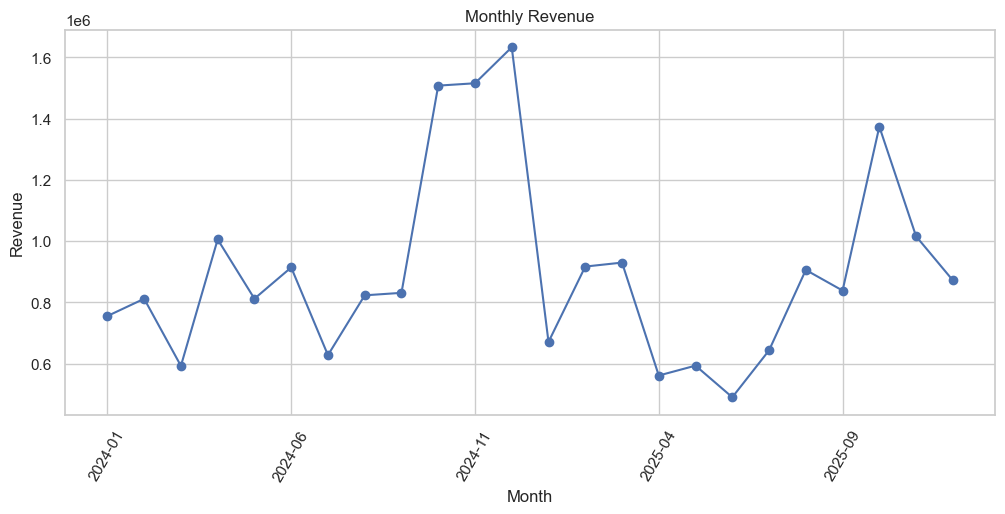

In [23]:
monthly = clean.groupby("year_month")["revenue"].sum()

monthly.plot(kind="line", marker="o", figsize=(12, 5))
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=60)
plt.show()

👉 *Look for the peak. Which months are highest? (Festival season: Oct–Dec)*

### Q3. Which category earns the most?

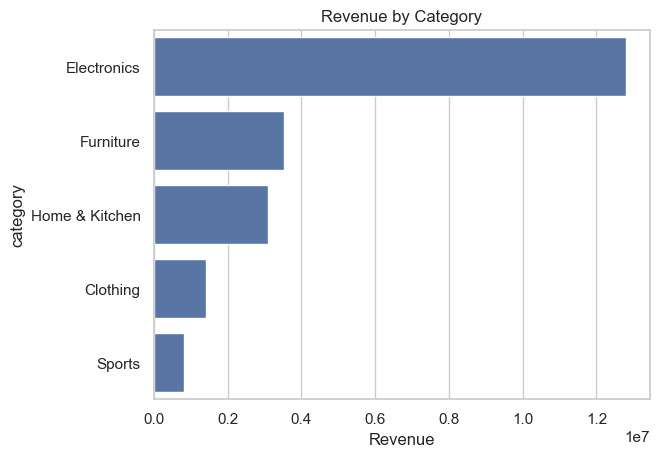

In [24]:
cat_rev = clean.groupby("category")["revenue"].sum().sort_values(ascending=False)

sns.barplot(x=cat_rev.values, y=cat_rev.index)
plt.title("Revenue by Category")
plt.xlabel("Revenue")
plt.show()

### Q4. Which region is best?

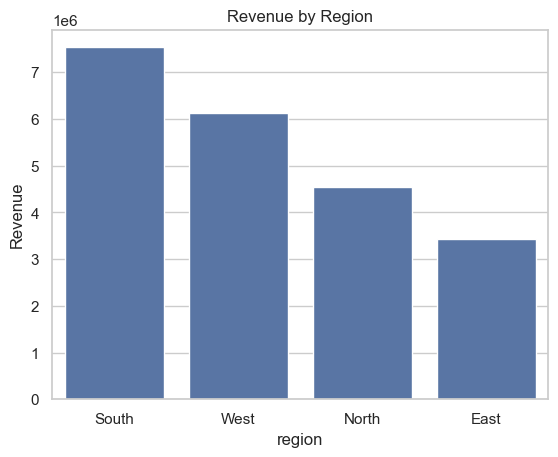

In [25]:
region_rev = clean.groupby("region")["revenue"].sum().sort_values(ascending=False)

sns.barplot(x=region_rev.index, y=region_rev.values)
plt.title("Revenue by Region")
plt.ylabel("Revenue")
plt.show()

### Q5. Top 5 products

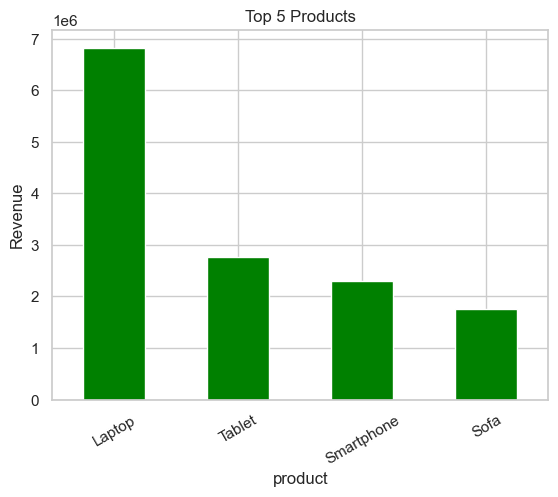

In [28]:
top5 = clean.groupby("product")["revenue"].sum().sort_values(ascending=False).head(4)
top5.plot(kind="bar", color="green")
plt.title("Top 5 Products")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.show()

### Q6. Which payment method is most used?

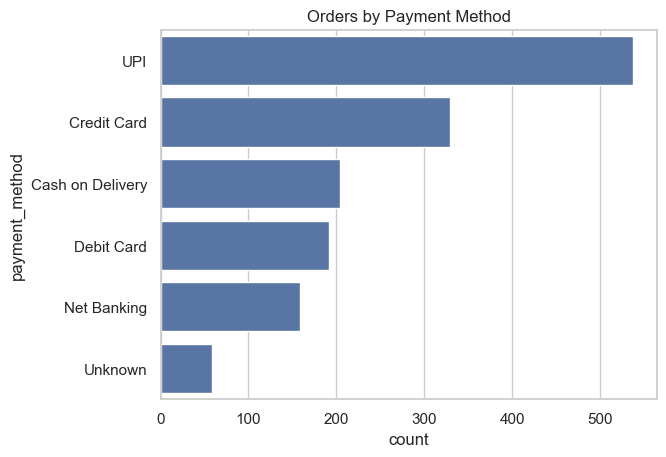

In [29]:
sns.countplot(data=clean, y="payment_method", order=clean["payment_method"].value_counts().index)
plt.title("Orders by Payment Method")
plt.show()

👉 *Do higher discounts really increase quantity? Here the bars are about the same, so discounts mostly just reduce our revenue.*

### Q7. Which age group spends the most?

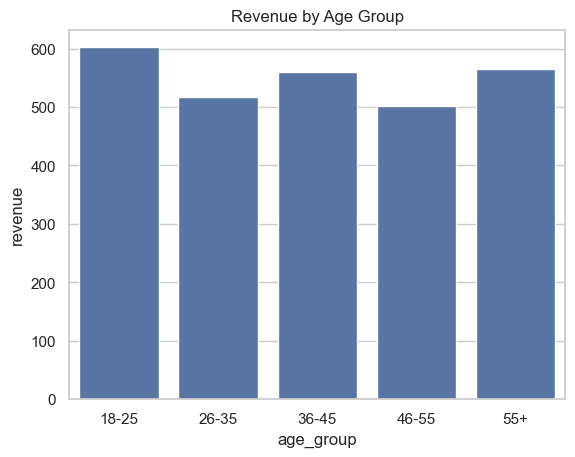

In [36]:
sns.barplot(data=clean, x="age_group", y="revenue", estimator="min", errorbar=None)
plt.title("Revenue by Age Group")
plt.show()

## Step 6: Conclusions

In [37]:
print("Best category :", cat_rev.idxmax())
print("Best region   :", region_rev.idxmax())
print("Best month    :", clean.groupby("month_name")["revenue"].sum().idxmax())
print("Top payment   :", clean["payment_method"].value_counts().idxmax())

Best category : Electronics
Best region   : South
Best month    : Oct
Top payment   : UPI
